In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


def _encontrar_raiz_repositorio(marcador: str = "src") -> Path:
    """Sobe os diretórios a partir do diretório atual até achar a raiz do repositório
    (identificada pela pasta "src" existir ali).

    Necessário porque o kernel do Jupyter/VS Code usa a pasta do notebook como
    base — não a raiz do projeto — e isso varia por máquina/configuração, ao
    contrário de rodar via `python -m`, que sempre parte da raiz.
    """
    atual = Path.cwd()
    for pasta in [atual, *atual.parents]:
        if (pasta / marcador).is_dir():
            return pasta
    raise RuntimeError(f"Não foi possível localizar a raiz do repositório (procurando por '{marcador}').")


sys.path.append(str(_encontrar_raiz_repositorio()))

from src.forecast import carregar_mart
from src.forecast.data import _conectar

PASTA_SAIDA = "../../apresentacao_exports"
import os
os.makedirs(PASTA_SAIDA, exist_ok=True)


def run_query(query: str) -> pd.DataFrame:
    """Executa uma query no SQL Warehouse e retorna um DataFrame pandas."""
    connection = _conectar()
    with connection.cursor() as cursor:
        cursor.execute(query)
        if cursor.description is None:
            return pd.DataFrame()
        rows = cursor.fetchall()
        columns = [desc[0] for desc in cursor.description]
        return pd.DataFrame(rows, columns=columns)

# LH Nautical — Consolidação das 4 Perguntas de Negócio e Critérios de Avaliação

Fonte única para a apresentação final — cada seção abaixo corresponde a uma
pergunta de negócio oficial ou a um critério de avaliação.
Gráficos são salvos automaticamente em `apresentacao_exports/`,
prontos para importar no PowerPoint.

[WARN] pyarrow is not installed by default since databricks-sql-connector 4.0.0,any arrow specific api (e.g. fetchmany_arrow) and cloud fetch will be disabled.If you need these features, please run pip install pyarrow or pip install databricks-sql-connector[pyarrow] to install


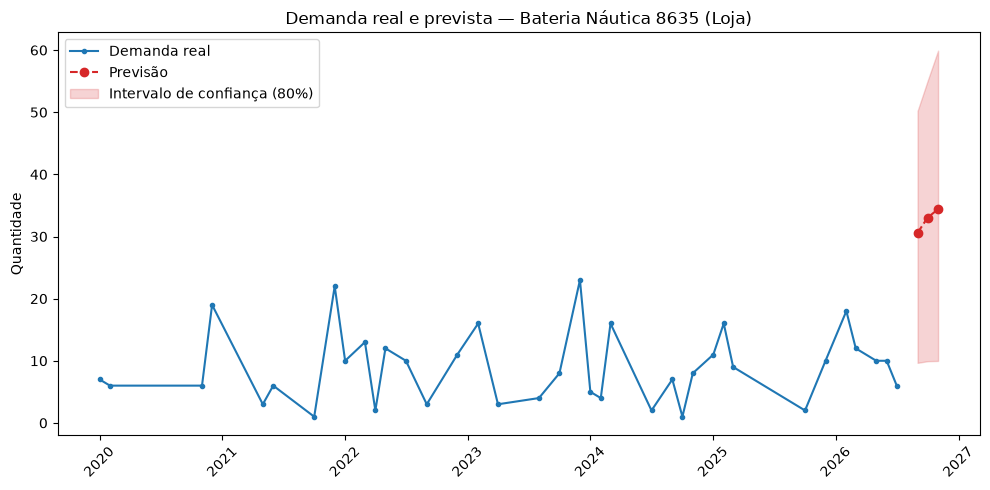

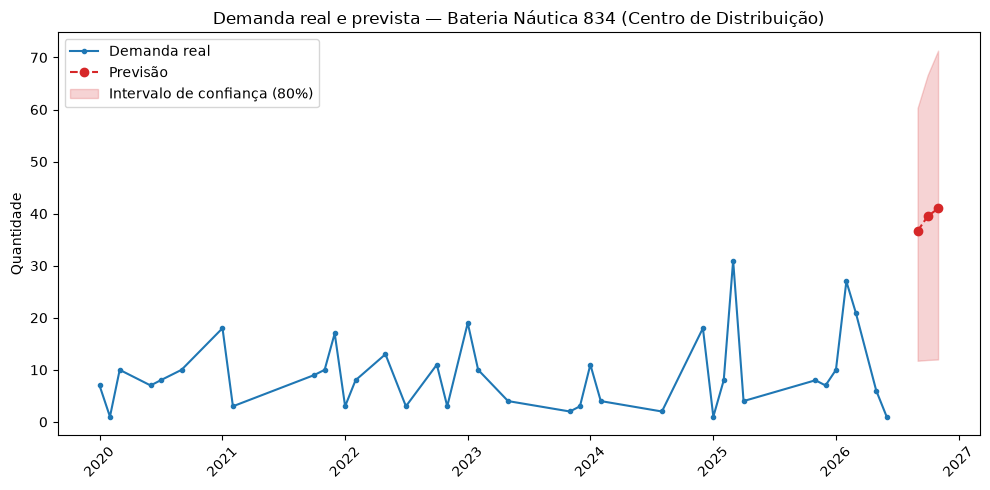

In [ ]:
def grafico_previsao_produto(pipeline: str, product_variant_id: int, nome_produto: str):
    """Gera o gráfico de série temporal (real + previsão + banda de confiança) de um produto.

    Args:
        pipeline: "store" ou "warehouse".
        product_variant_id: variante do produto sazonal (396 ou 341).
        nome_produto: nome legível, para o título do gráfico.
    """
    historico = carregar_mart(pipeline)
    historico["mes_ref"] = pd.to_datetime(historico["mes_ref"])
    historico_produto = (
        historico[historico["product_variant_id"] == product_variant_id]
        .groupby("mes_ref")["quantidade_mes"].sum()
        .reset_index()
    )

    previsao = run_query(f"""
        SELECT mes_ref,
               SUM(previsao_pontual) AS previsao_pontual,
               SUM(previsao_p10) AS previsao_p10,
               SUM(previsao_p90) AS previsao_p90
        FROM dev.gold.fct_previsao_demanda
        WHERE product_variant_id = {product_variant_id}
        GROUP BY mes_ref
        ORDER BY mes_ref
    """)
    previsao["mes_ref"] = pd.to_datetime(previsao["mes_ref"])

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(historico_produto["mes_ref"], historico_produto["quantidade_mes"],
            label="Demanda real", color="#1f77b4", marker="o", markersize=3)
    ax.plot(previsao["mes_ref"], previsao["previsao_pontual"],
            label="Previsão", color="#d62728", linestyle="--", marker="o")
    ax.fill_between(previsao["mes_ref"], previsao["previsao_p10"], previsao["previsao_p90"],
                     color="#d62728", alpha=0.2, label="Intervalo de confiança (80%)")
    ax.set_title(f"Demanda real e prevista — {nome_produto}")
    ax.set_ylabel("Quantidade")
    ax.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f"{PASTA_SAIDA}/previsao_{pipeline}_{product_variant_id}.png", dpi=150)
    plt.show()


# Os dois produtos sazonais confirmados
grafico_previsao_produto("store", 396, "Bateria Náutica 8635 (Loja)")
grafico_previsao_produto("warehouse", 341, "Bateria Náutica 834 (Centro de Distribuição)")

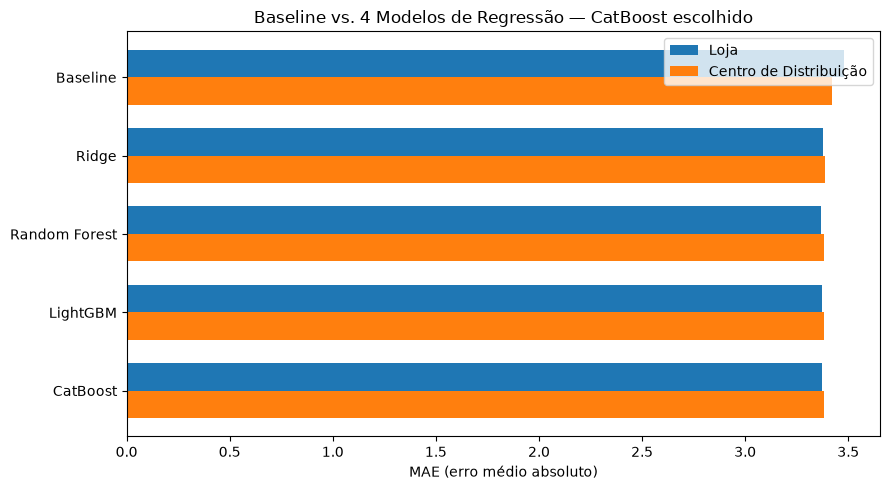

Modelo escolhido: CatBoost — vantagem estrutural (categórica nativa), diferenças entre os 4 modelos são pequenas (<0,2% de MAE). Ver Model Card, Seção 4.


In [ ]:
# Valores confirmados — ver docs/MODEL_CARD.md.
# Fonte: MLflow, experimento /Shared/forecast_lh_nautical/treino_modelos.
comparacao_modelos = pd.DataFrame({
    "modelo": ["Baseline", "Ridge", "Random Forest", "LightGBM", "CatBoost"],
    "mae_loja": [3.480, 3.378, 3.370, 3.373, 3.373],
    "mae_cd": [3.423, 3.387, 3.383, 3.384, 3.384],
})

fig, ax = plt.subplots(figsize=(9, 5))
y = range(len(comparacao_modelos))
ax.barh(y, comparacao_modelos["mae_loja"], height=0.35, label="Loja", color="#1f77b4")
ax.barh([i + 0.35 for i in y], comparacao_modelos["mae_cd"], height=0.35, label="Centro de Distribuição", color="#ff7f0e")
ax.set_yticks([i + 0.175 for i in y])
ax.set_yticklabels(comparacao_modelos["modelo"])
ax.set_xlabel("MAE (erro médio absoluto)")
ax.set_title("Baseline vs. 4 Modelos de Regressão — CatBoost escolhido")
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/comparacao_modelos.png", dpi=150)
plt.show()

print("Modelo escolhido: CatBoost — vantagem estrutural (categórica nativa), "
      "diferenças entre os 4 modelos são pequenas (<0,2% de MAE). Ver Model Card.")

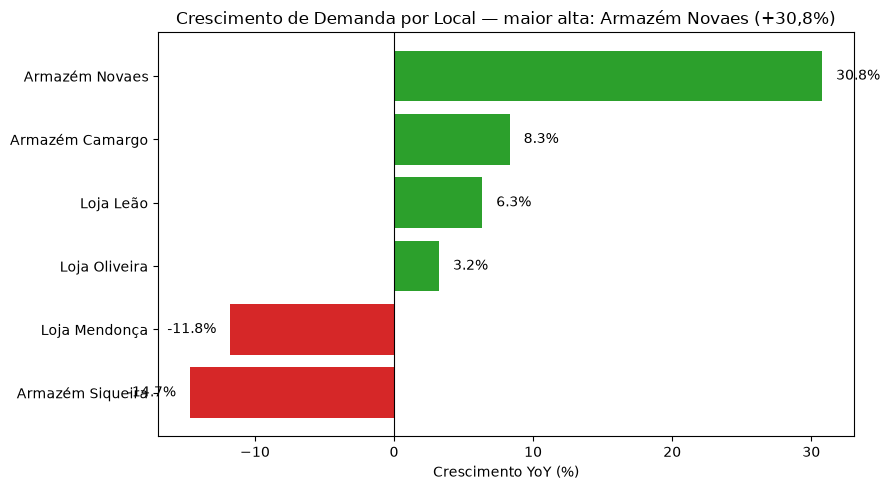

In [ ]:
# Valores confirmados — ver docs/MODEL_CARD.md.
crescimento = pd.DataFrame({
    "local": ["Loja Leão", "Loja Oliveira", "Loja Mendonça", "Armazém Novaes", "Armazém Camargo", "Armazém Siqueira"],
    "tipo": ["Loja", "Loja", "Loja", "Centro de Distribuição", "Centro de Distribuição", "Centro de Distribuição"],
    "crescimento_pct": [6.35, 3.24, -11.78, 30.78, 8.32, -14.68],
}).sort_values("crescimento_pct", ascending=True)

cores = ["#d62728" if v < 0 else "#2ca02c" for v in crescimento["crescimento_pct"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(crescimento["local"], crescimento["crescimento_pct"], color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Crescimento YoY (%)")
ax.set_title("Crescimento de Demanda por Local — maior alta: Armazém Novaes (+30,8%)")
for i, v in enumerate(crescimento["crescimento_pct"]):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:.1f}%", va="center", ha="left" if v >= 0 else "right")
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/crescimento_por_local.png", dpi=150)
plt.show()

In [ ]:
# Valores confirmados — ver docs/MODEL_CARD.md.
estados_avaliados = pd.DataFrame({
    "estado": ["PI", "AC", "TO", "RJ", "PA", "AP", "MA"],
    "demanda_trimestre_alvo": [796, 690, 707, 692, 602, 649, 576],
    "crescimento_pct": [-2.3, -4.3, -4.3, -9.9, -16.6, -22.6, -37.5],
    "cobertura": ["Sim", "Não", "Não", "Não", "Não", "Sim", "Não"],
})

print("CONCLUSÃO: Não há evidência que justifique a abertura de um novo "
      "Centro de Distribuição.\n")
print("Os 7 estados com volume relevante (acima do p75 de demanda) estão em "
      "DECLÍNIO, não crescimento — e o de maior volume (PI, 796 unidades) "
      "representa menos de 30% do volume de uma única loja/CD já existente.\n")
display(estados_avaliados)  # no VS Code, trocar por print(estados_avaliados.to_string(index=False))

CONCLUSÃO (B9): Não há evidência que justifique a abertura de um novo Centro de Distribuição.

Os 7 estados com volume relevante (acima do p75 de demanda) estão em DECLÍNIO, não crescimento — e o de maior volume (PI, 796 unidades) representa menos de 30% do volume de uma única loja/CD já existente.



,estado,demanda_trimestre_alvo,crescimento_pct,cobertura
0,PI,796,-2.3,Sim
1,AC,690,-4.3,Não
2,TO,707,-4.3,Não
3,RJ,692,-9.9,Não
4,PA,602,-16.6,Não
5,AP,649,-22.6,Sim
6,MA,576,-37.5,Não


In [ ]:
# Valores confirmados — ver docs/MODEL_CARD.md.
print("Multicolinearidade (Ridge/Lasso): VIF infinito entre lag_1/lag_2/lag_3/rolling_mean_3 "
      "— combinação linear exata por construção das features. Argumento a favor de "
      "modelo baseado em árvore (CatBoost).\n")

print("Overfitting (Random Forest, LightGBM, CatBoost): gap pequeno e positivo "
      "(treino levemente melhor que validação) — padrão saudável, sem overfitting, "
      "nos dois pipelines.\n")

print("Resíduos do CatBoost: média levemente positiva nos dois pipelines (leve viés de "
      "subestimação, mais presente em picos de alta temporada — ver Model Card).")

Multicolinearidade (Ridge/Lasso): VIF infinito entre lag_1/lag_2/lag_3/rolling_mean_3 — combinação linear exata por construção das features (A6). Argumento a favor de modelo baseado em árvore (CatBoost).

Overfitting (Random Forest, LightGBM, CatBoost): gap pequeno e positivo (treino levemente melhor que validação) — padrão saudável, sem overfitting, nos dois pipelines.

Resíduos do CatBoost: média levemente positiva nos dois pipelines (leve viés de subestimação, mais presente em picos de alta temporada — ver Model Card, Seção 6).
